# Random Forest Model

CRISP-DM phase: Modelling + Evaluation

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score, precision_score

### 1.2 Loading the Training and Test Sets

In [2]:
#loading the saved training and test sets
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

In [3]:
#separating the features (X) from the level (y)
X_train = train.drop('level', axis=1)
y_train = train['level']
X_test = test.drop('level', axis=1)
y_test = test['level']

## 2. Cross-Validation

In [4]:
#stratified 5-fold cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 3. Base Model

In [5]:
#base model with all default settings
model_default = RandomForestClassifier(random_state=42)

In [6]:
#cross-validation predictions for the default model
y_pred_default = cross_val_predict(model_default, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_default, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.87      0.89      0.88      9546
             1 mild       0.70      0.72      0.71      4827
2 moderate or worse       0.81      0.56      0.66      1027

           accuracy                           0.81     15400
          macro avg       0.79      0.72      0.75     15400
       weighted avg       0.81      0.81      0.81     15400



#### Observation

With all default settings, the Random Forest reaches a macro F1 of 0.75 and an accuracy of 81%. It finds 89% of okay students and 72% of mild students, but only 56% of moderate or worse students, so about 450 of the 1,027 students who need help most are missed. Its precision for level 2 is high (81%), which means the forest only predicts level 2 when it is very sure, and it misses many level 2 students as a result.

This happens because the levels are imbalanced: there are about nine okay students for every moderate or worse student, so the trees learn mostly from the bigger levels. Since missing a level 2 student is the worst mistake for a screening app, the next step adds class weights to try to improve level 2 recall.

## 4. Class Weights


In [7]:
#model with balanced class weights
model_balanced = RandomForestClassifier(class_weight='balanced', random_state=42)
y_pred_balanced = cross_val_predict(model_balanced, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_balanced, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.91      0.83      0.87      9546
             1 mild       0.66      0.78      0.72      4827
2 moderate or worse       0.70      0.63      0.66      1027

           accuracy                           0.81     15400
          macro avg       0.76      0.75      0.75     15400
       weighted avg       0.82      0.81      0.81     15400



In [8]:
#model with balanced_subsample class weights
model_subsample = RandomForestClassifier(class_weight='balanced_subsample', random_state=42)
y_pred_subsample = cross_val_predict(model_subsample, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_subsample, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.88      0.88      0.88      9546
             1 mild       0.69      0.74      0.71      4827
2 moderate or worse       0.79      0.55      0.65      1027

           accuracy                           0.81     15400
          macro avg       0.78      0.72      0.74     15400
       weighted avg       0.81      0.81      0.81     15400



#### Observation

Balanced class weights raise level 2 recall from 56% to 63%, so about 380 of the 1,027 moderate or worse students are missed instead of about 450. The forest finds about 70 more of the students who need help most. The price is a lower precision for level 2 (70% instead of 81%), which means about 275 false alarms instead of about 135. Recall for mild students rises from 72% to 78% and recall for okay students falls from 89% to 83%, while macro F1 stays at 0.75 and accuracy at 81%.

The balanced_subsample option gives almost the same result as the default forest: level 2 recall is 55%, precision is 79% and macro F1 is 0.74. Recalculating the weights for each tree therefore did not help here. It is not clear from these results why the two options differ this much, so we only report the difference. We keep class_weight='balanced', because it finds the most level 2 students, which is the main aim.

## 5. Number of Trees

### 5.1 Comparing Numbers of Trees


In [9]:
#cross-validation with n_estimators = 50 (few trees)
model_n50 = RandomForestClassifier(class_weight='balanced', n_estimators=50, random_state=42)
scores_n50 = cross_val_score(model_n50, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_n50.round(3))
print(scores_n50.mean().round(3), scores_n50.std().round(3))


[0.739 0.762 0.763 0.726 0.735]
0.745 0.015


In [10]:
#cross-validation with n_estimators = 100 (default)
model_n100 = RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
scores_n100 = cross_val_score(model_n100, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_n100.round(3))
print(scores_n100.mean().round(3), scores_n100.std().round(3))


[0.746 0.768 0.757 0.736 0.737]
0.749 0.012


In [11]:
#cross-validation with n_estimators = 200
model_n200 = RandomForestClassifier(class_weight='balanced', n_estimators=200, random_state=42)
scores_n200 = cross_val_score(model_n200, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_n200.round(3))
print(scores_n200.mean().round(3), scores_n200.std().round(3))


[0.748 0.771 0.76  0.736 0.74 ]
0.751 0.013


In [12]:
#cross-validation with n_estimators = 300 (many trees)
model_n300 = RandomForestClassifier(class_weight='balanced', n_estimators=300, random_state=42)
scores_n300 = cross_val_score(model_n300, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_n300.round(3))
print(scores_n300.mean().round(3), scores_n300.std().round(3))


[0.749 0.766 0.763 0.731 0.741]
0.75 0.013


In [13]:
#comparing the four numbers of trees
cv_results = pd.DataFrame({'n_estimators': [50, 100, 200, 300],
                           'mean recall_macro': [scores_n50.mean(), scores_n100.mean(), scores_n200.mean(), scores_n300.mean()],
                           'std': [scores_n50.std(), scores_n100.std(), scores_n200.std(), scores_n300.std()]})
cv_results.round(4)

,n_estimators,mean recall_macro,std
0,50,0.7449,0.0150
1,100,0.7490,0.0123
2,200,0.7509,0.0128
3,300,0.7500,0.0130


#### Observation

The score barely changes with the number of trees. The mean recall_macro rises from 0.745 with 50 trees to 0.749 with 100 and 0.751 with 200, and then stays flat at 0.750 with 300, so the forest stops improving after about 100 to 200 trees. The whole difference between 50 and 200 trees (0.006) is smaller than the standard deviation between folds (about 0.013), so the four settings are effectively tied.

We chose n_estimators = 50 because it is the smallest forest within one standard deviation of the best (200 trees, 0.751). Fewer trees means a smaller model to store and run on the phone. The gain from more trees is small: 100 trees scored higher than 50 trees in 4 of the 5 folds, but only by about 0.004 on average.


### 5.2 Size of the Forest


In [14]:
#cross-validation predictions for the forest with 50 trees
y_pred_n50 = cross_val_predict(model_n50, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_n50, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.91      0.84      0.87      9546
             1 mild       0.66      0.79      0.72      4827
2 moderate or worse       0.71      0.61      0.66      1027

           accuracy                           0.81     15400
          macro avg       0.76      0.74      0.75     15400
       weighted avg       0.82      0.81      0.81     15400



In [15]:
#fitting the forest on the full training set
model_n50.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1

In [16]:
#how deep one tree of the forest grew and how many leaves it has
print(model_n50.estimators_[0].get_depth())
print(model_n50.estimators_[0].get_n_leaves())

37
2995


In [17]:
#accuracy on the training students it learned from
print(round(model_n50.score(X_train, y_train), 3))

0.968


#### Observation

One tree of the forest grew to a depth of 37 with 2,995 leaves. Its training sample has 15,400 students, so that is only about 5 students per leaf, and the tree has split the students into very small groups. A depth of 37 is more than the 21 questions in the app, because a tree can reuse the same question at different cut-off points.

The forest's accuracy on the training students is 96.8%, but on unseen students in cross-validation it is 81%. This gap of about 16 percentage points shows that the forest is overfitting: its trees have memorised the training students. The accuracy does not reach 100%, and the likely reasons are that some students gave identical answers but have different levels, and that each student was left out of the sample of some of the trees, so those trees never saw them. These results do not show how much each reason contributes.

With 50 trees, the cross-validation report shows level 2 recall of 61% (about 400 of the 1,027 students missed) and precision of 71%, compared with 63% and 70% in Section 4 with 100 trees. Using 50 trees therefore costs about 20 level 2 students, but halves the size of the forest. If every tree is about as large as this one, the forest has roughly 150,000 leaves, which is a lot to store on a phone. The next section limits the depth of the trees to make them smaller and to reduce overfitting.

## 6. Choosing max_depth

### 6.1 Comparing Depths

In [18]:
#cross-validation with max_depth = 3 (very shallow trees)
model_d3 = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=3, random_state=42)
scores_d3 = cross_val_score(model_d3, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_d3.round(3))
print(scores_d3.mean().round(3), scores_d3.std().round(3))

[0.772 0.785 0.777 0.77  0.76 ]
0.773 0.008


In [19]:
#cross-validation with max_depth = 5
model_d5 = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=5, random_state=42)
scores_d5 = cross_val_score(model_d5, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_d5.round(3))
print(scores_d5.mean().round(3), scores_d5.std().round(3))

[0.777 0.797 0.782 0.781 0.778]
0.783 0.007


In [20]:
#cross-validation with max_depth = 7
model_d7 = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=7, random_state=42)
scores_d7 = cross_val_score(model_d7, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_d7.round(3))
print(scores_d7.mean().round(3), scores_d7.std().round(3))


[0.78  0.803 0.789 0.771 0.786]
0.786 0.011


In [21]:
#cross-validation with max_depth = 10
model_d10 = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=10, random_state=42)
scores_d10 = cross_val_score(model_d10, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_d10.round(3))
print(scores_d10.mean().round(3), scores_d10.std().round(3))


[0.776 0.801 0.793 0.771 0.782]
0.785 0.011


In [22]:
#cross-validation with max_depth = 15 (deep trees)
model_d15 = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=15, random_state=42)
scores_d15 = cross_val_score(model_d15, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_d15.round(3))
print(scores_d15.mean().round(3), scores_d15.std().round(3))


[0.76  0.786 0.771 0.747 0.753]
0.763 0.014


In [23]:
#cross-validation with max_depth = 20 (very deep trees)
model_d20 = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=20, random_state=42)
scores_d20 = cross_val_score(model_d20, X_train, y_train, cv=cv, scoring='recall_macro')
print(scores_d20.round(3))
print(scores_d20.mean().round(3), scores_d20.std().round(3))


[0.752 0.764 0.76  0.737 0.731]
0.749 0.013


In [24]:
#comparing the six depths
cv_results = pd.DataFrame({'max_depth': [3, 5, 7, 10, 15, 20],
                           'mean recall_macro': [scores_d3.mean(), scores_d5.mean(), scores_d7.mean(), scores_d10.mean(), scores_d15.mean(), scores_d20.mean()],
                           'std': [scores_d3.std(), scores_d5.std(), scores_d7.std(), scores_d10.std(), scores_d15.std(), scores_d20.std()]})
cv_results.round(4)


,max_depth,mean recall_macro,std
0,3,0.7728,0.0081
1,5,0.7831,0.0072
2,7,0.7857,0.0105
3,10,0.7846,0.0110
4,15,0.7633,0.0138
5,20,0.7489,0.0127


#### Observation

Limiting the depth of the trees clearly helps. The forest with unlimited trees had a mean recall_macro of 0.745, while depths 5, 7 and 10 all score about 0.785 (0.783, 0.786 and 0.785). Depth 7 has the highest mean, but depth 5 and depth 10 are well within one standard deviation of it (about 0.011), so the three are effectively tied.

At depth 3 the score drops to 0.773, more than one standard deviation below the best, so trees with only 3 questions in a row are too simple (underfitting). From depth 15 the score falls again (0.763 at depth 15 and 0.749 at depth 20, close to the unlimited forest), because deeper trees start to memorise the training students (overfitting). The best depths are therefore in the middle.

We chose max_depth = 5 because it is the simplest of the tied depths, so its trees are the smallest and overfit the least, and it also has the lowest standard deviation between folds (0.007). Depth 7 scored higher in 4 of the 5 folds, but only by about 0.003 on average. Section 6.2 checks how much of the improvement over the unlimited forest comes from the class weights.


### 6.2 Class Weights at the Chosen Depth


In [25]:
#chosen depth without class weights
model_noweights = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42)
y_pred_noweights = cross_val_predict(model_noweights, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_noweights, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.87      0.91      0.89      9546
             1 mild       0.71      0.72      0.71      4827
2 moderate or worse       0.91      0.38      0.54      1027

           accuracy                           0.82     15400
          macro avg       0.83      0.67      0.71     15400
       weighted avg       0.82      0.82      0.81     15400



In [26]:
#chosen depth with class weights
model_tuned = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=5, random_state=42)
y_pred_tuned = cross_val_predict(model_tuned, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_tuned, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.93      0.81      0.87      9546
             1 mild       0.65      0.74      0.69      4827
2 moderate or worse       0.54      0.80      0.64      1027

           accuracy                           0.79     15400
          macro avg       0.70      0.78      0.73     15400
       weighted avg       0.81      0.79      0.80     15400



In [27]:
#chosen depth with subsample class weights
model_sub_n50 = RandomForestClassifier(class_weight='balanced_subsample', n_estimators=50, max_depth=5, random_state=42)
y_pred_sub_n50 = cross_val_predict(model_sub_n50, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_sub_n50, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.93      0.80      0.86      9546
             1 mild       0.64      0.74      0.68      4827
2 moderate or worse       0.54      0.80      0.64      1027

           accuracy                           0.78     15400
          macro avg       0.70      0.78      0.73     15400
       weighted avg       0.81      0.78      0.79     15400



In [28]:
#chosen depth with subsample class weights and 200 trees
model_sub_n200 = RandomForestClassifier(class_weight='balanced_subsample', n_estimators=200, max_depth=5, random_state=42)
y_pred_sub_n200 = cross_val_predict(model_sub_n200, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_sub_n200, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.93      0.81      0.86      9546
             1 mild       0.64      0.74      0.69      4827
2 moderate or worse       0.54      0.79      0.64      1027

           accuracy                           0.79     15400
          macro avg       0.70      0.78      0.73     15400
       weighted avg       0.81      0.79      0.79     15400



In [29]:
#chosen depth with class weights and 200 trees
model_bal_n200 = RandomForestClassifier(class_weight='balanced', n_estimators=200, max_depth=5, random_state=42)
y_pred_bal_n200 = cross_val_predict(model_bal_n200, X_train, y_train, cv=cv)
print(classification_report(y_train, y_pred_bal_n200, target_names=['0 okay', '1 mild', '2 moderate or worse']))


                     precision    recall  f1-score   support

             0 okay       0.93      0.81      0.86      9546
             1 mild       0.64      0.74      0.69      4827
2 moderate or worse       0.53      0.81      0.64      1027

           accuracy                           0.79     15400
          macro avg       0.70      0.78      0.73     15400
       weighted avg       0.81      0.79      0.79     15400



In [33]:
#exact recall per level for 50 and 200 trees
print(recall_score(y_train, y_pred_tuned, average=None).round(4))
print(recall_score(y_train, y_pred_bal_n200, average=None).round(4))

[0.8111 0.7398 0.7984]
[0.8083 0.7386 0.8062]


#### Observation

At a depth of 5, the class weights make a very large difference. Without weights, the forest finds only 38% of moderate or worse students (about 640 missed), even though its level 2 precision is very high (91%). With balanced weights, level 2 recall rises to 80% (about 205 missed), so the forest finds about 435 more of the students who need help most. The price is a lower level 2 precision (54%), which means about 700 false alarms instead of about 40. Recall for okay students falls from 91% to 81% and accuracy from 82% to 79%, while macro F1 rises from 0.71 to 0.73.

The effect is much larger than for the unlimited forest in Section 4 (56% to 63%), and the weights are likely more effective now because the shallow trees have leaves that hold a mix of levels, which the weights can tip towards level 2. Since recall for level 2 is the main aim, we keep the class weights.

We also repeated the check at this depth for the other settings. The balanced_subsample option gives the same level 2 result as balanced (80% recall and 54% precision), and using 200 trees instead of 50 changes level 2 recall by at most 1 percentage point (about 10 students). So the final forest is n_estimators = 50, max_depth = 5 and class_weight = 'balanced'.


### 6.3 Size of the Tuned Forest


In [30]:
#fitting the tuned forest on the full training set
model_tuned.fit(X_train, y_train)
print(model_tuned.estimators_[0].get_depth())
print(model_tuned.estimators_[0].get_n_leaves())

5
30


In [31]:
#training accuracy of the tuned forest, to compare with its cross-validation accuracy
print(round(model_tuned.score(X_train, y_train), 3))

0.791


#### Observation

One tree of the tuned forest has a depth of 5 and 30 leaves, close to the 32 that a depth-5 tree can have at most. With 15,400 training students, that is about 510 students per leaf on average, compared with about 5 per leaf in the unlimited forest (2,995 leaves per tree). If every tree is about the size of this one, the whole forest has about 1,500 leaves, roughly 100 times fewer than the unlimited forest (about 150,000), so it is much easier to store and run inside the app.

The training accuracy is now 79.1%, almost the same as the cross-validation accuracy of 79%. In Section 5.2 the gap was about 16 percentage points (96.8% against 81%), so limiting the depth has removed the overfitting: the forest now does as well on new students as on the students it learned from. The cross-validation accuracy itself fell from 81% to 79%, because the class weights give up some accuracy to find more level 2 students.


## 7. Evaluation on the Test Set

### 7.1 Fitting the Final Random Forest

After the previous tests, the best settings for the random forest were found to be n_estimators = 50, max_depth = 5 and balanced class weights. These settings are used for the final model on the test data.


In [38]:
#fitting on the full training set and predicting the test set
model = RandomForestClassifier(class_weight='balanced', n_estimators=50, max_depth=5, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

### 7.2 Classification Report


In [39]:
#per-class recall, precision and f1 on the test set
print(classification_report(y_test, y_pred, target_names=['0 okay', '1 mild', '2 moderate or worse']))

                     precision    recall  f1-score   support

             0 okay       0.93      0.82      0.87      2387
             1 mild       0.64      0.72      0.68      1207
2 moderate or worse       0.49      0.79      0.60       257

           accuracy                           0.78      3851
          macro avg       0.69      0.77      0.72      3851
       weighted avg       0.81      0.78      0.79      3851



In [ ]:
#macro recall on the test set, to compare with the cross-validation score
print(round(recall_score(y_test, y_pred, average='macro'), 3))

0.774


#### Observation

On the test set the forest finds 79% of moderate or worse students (202 of 257), so 55 are missed, close to the 80% found in cross-validation. Recall is 82% for okay students and 72% for mild students. The macro recall is 0.77, about 0.01 below the cross-validation score of 0.783, so the cross-validation was a reasonably reliable guide.

The precision for level 2 is 49%, lower than the 54% in cross-validation, so about half of the students the forest flags as level 2 (214 of 416) are really mild or okay. It is not clear why precision dropped by 5 points. It may partly be chance, because the test set has only 257 level 2 students, but these results cannot confirm this. Predictions of okay are very reliable (precision 93%), but the forest predicts mild too often (precision 64%).


### 7.3 Confusion Matrix

Each row is the true level and each column is the predicted level, so the numbers on the diagonal are correct predictions.


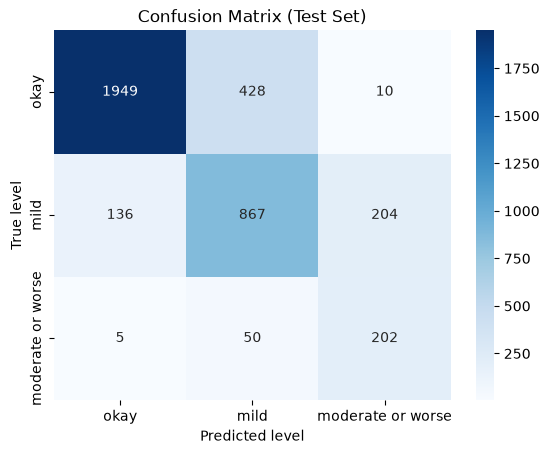

In [40]:
#confusion matrix of the test set
level_names = ['okay', 'mild', 'moderate or worse']
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=level_names, yticklabels=level_names)
plt.xlabel('Predicted level')
plt.ylabel('True level')
plt.title('Confusion Matrix (Test Set)')
plt.show()


#### Observation

Of the 2,387 okay students, 1,949 are correct (82%), 428 are predicted mild and 10 are predicted level 2. Of the 1,207 mild students, 867 are correct (72%), 136 are predicted okay and 204 are predicted level 2. Of the 257 level 2 students, 202 are found (79%), 50 are predicted mild and 5 are predicted okay.

The biggest single mistake is okay students predicted as mild (428, about 18% of okay students). Most of the false alarms for level 2 are mild students (204 of 214, which is 17% of all mild students), and 50 of the 55 missed level 2 students were still predicted mild, so the boundary between mild and moderate or worse is the hardest one. The 204 mild students flagged as level 2 are the price of finding 79% of the level 2 students.

Most mistakes are between neighbouring levels. Only 15 students are two levels away (10 okay students predicted as level 2 and 5 level 2 students predicted as okay), which is 0.4% of the test set.


## 8. Comparison with the PHQ-2 Baseline

The PHQ-2 rule (the first two PHQ-9 questions added up, positive when 3 or more) is a yes/no rule, so it is compared with the model only on finding level 2 (moderate or worse) against everyone else. The cells below use the same test set.


In [42]:
#phq-2 rule on the test set: score of 3 or more = possible level 2
phq2_pred = (X_test['phq_q1'] + X_test['phq_q2']) >= 3


In [43]:
#level 2 recall and precision for the phq-2 rule and for the random forest
comparison = pd.DataFrame({'method': ['PHQ-2 rule', 'Random forest'],
                           'level 2 recall': [recall_score(y_test == 2, phq2_pred), recall_score(y_test == 2, y_pred == 2)],
                           'level 2 precision': [precision_score(y_test == 2, phq2_pred), precision_score(y_test == 2, y_pred == 2)]})
comparison.round(3)


,method,level 2 recall,level 2 precision
0,PHQ-2 rule,0.638,0.636
1,Random forest,0.786,0.486


#### Observation

On the test set the PHQ-2 rule finds 63.8% of level 2 students (164 of 257) with a precision of 63.6%. The random forest finds 78.6% (202 of 257), which is 38 more students, but its precision is lower at 48.6%. It raises 214 false alarms against 94 for the PHQ-2 rule (120 more), which is about 3 extra false alarms for each extra level 2 student found, and most of the forest's false alarms are mild students (204 of 214). So the forest beats the baseline on the main aim, recall for level 2, at the price of lower precision, and it can also separate level 0 from level 1, which the rule cannot do.


## 9. Looking Inside the Forest

### 9.1 Feature Importance


In [44]:
#how much each question helped the forest, sorted from most to least important
importance = pd.DataFrame({'question': X_train.columns, 'importance': model.feature_importances_})
importance = importance.sort_values('importance', ascending=False)
importance.round(3)


,question,importance
1,phq_q1,0.243
0,phq_q2,0.222
3,gad_q2,0.087
2,gad_q6,0.076
7,pss_q2,0.070
5,gad_q4,0.055
4,gad_q3,0.047
8,pss_q3,0.041
9,pss_q1,0.031
6,gad_q1,0.030


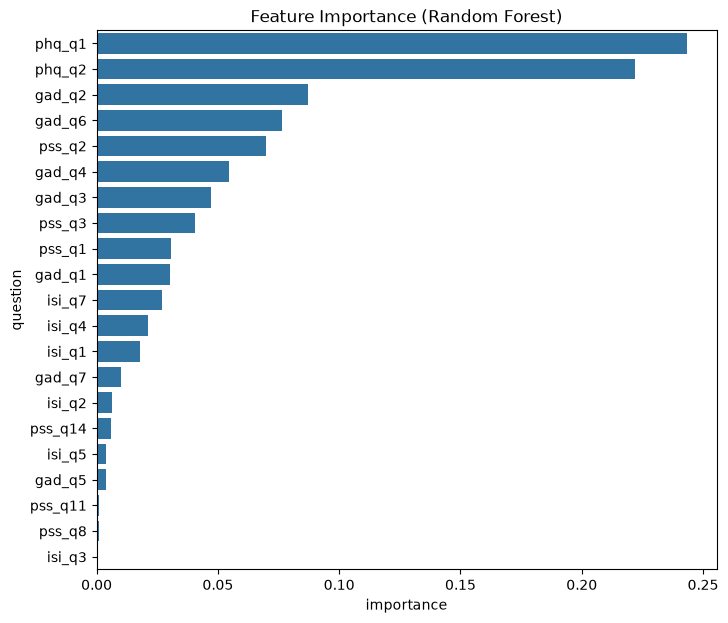

In [45]:
#bar chart of the importance of each question
plt.figure(figsize=(8, 7))
sns.barplot(data=importance, x='importance', y='question')
plt.title('Feature Importance (Random Forest)')
plt.show()


#### Observation

The forest relies most on the two PHQ questions: phq_q1 has an importance of about 0.24 and phq_q2 about 0.22, so together they account for about 46% of its decisions. This is expected, because the level comes from the full PHQ-9, and these are the only two PHQ-9 questions in the features. The rest is spread over the other questionnaires: the seven GAD questions add up to about 31%, the six PSS questions to about 15% and the six ISI questions to about 8%. The most useful single questions after the PHQ ones are gad_q2 (0.087), gad_q6 (0.076) and pss_q2 (0.070). These extra questions are what allow the forest to do more than the PHQ-2 rule, which uses only phq_q1 and phq_q2.

Almost every question contributes something: only one of the 21 (isi_q3) has an importance that rounds to 0.000. The importance is likely spread widely because each split can only choose from 4 randomly picked questions, so the other questionnaires get used often. A low importance does not mean a question is useless: if two questions carry similar information, the forest may use one more than the other, so these importances should not be used on their own to remove questions from the app.


### 9.2 Drawing One Tree of the Forest


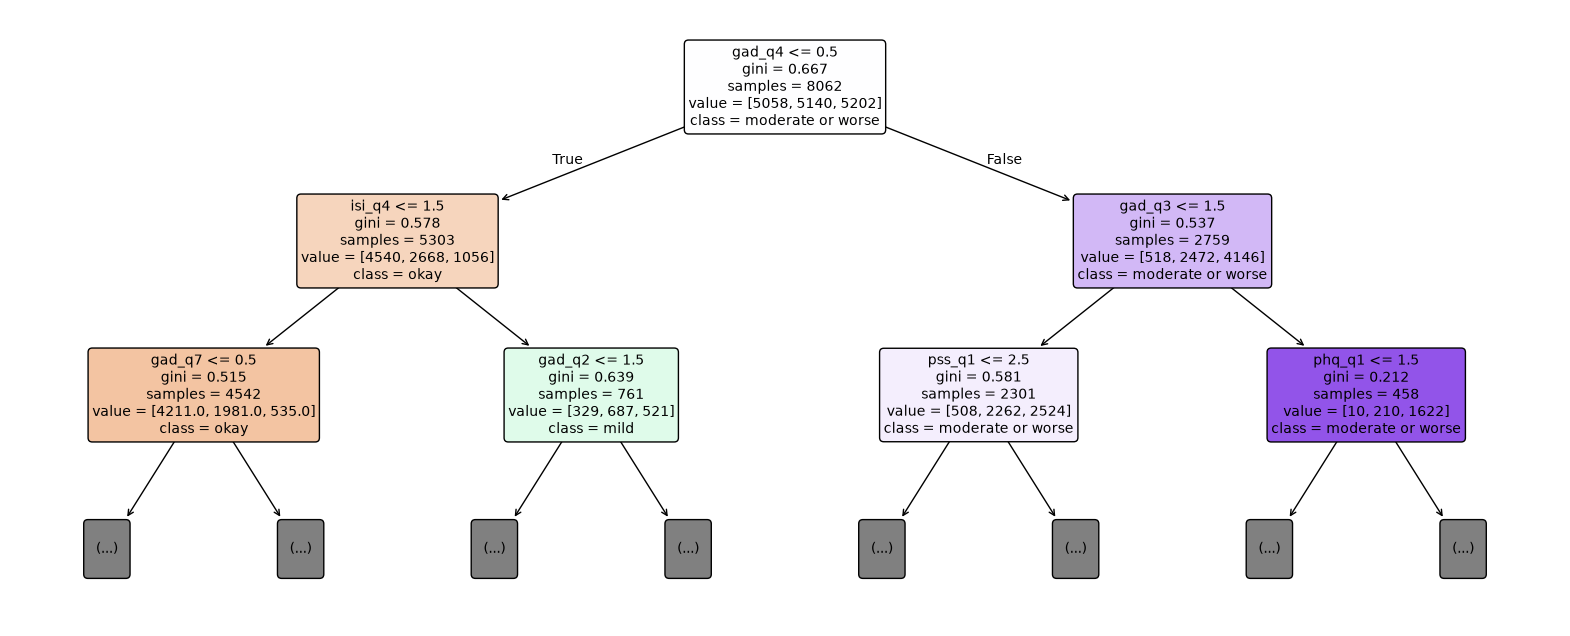

In [46]:
#top three levels of the first tree of the forest
plt.figure(figsize=(20, 8))
plot_tree(model.estimators_[0], max_depth=2, feature_names=X_train.columns, class_names=['okay', 'mild', 'moderate or worse'], filled=True, rounded=True, fontsize=10)
plt.show()


#### Observation

This is only one of the 50 trees, so it shows how the trees in the forest work and not the whole model. Its first question is gad_q4 ≤ 0.5, meaning whether the student answered 0 to the fourth GAD question, and not a PHQ question. Each split can only choose from 4 randomly picked questions out of 21, so a tree does not always start with the most important question, and gad_q4 is only the 6th most important question of the whole forest (0.055).

At the top the Gini is 0.667, the highest possible for three levels, because the class weights make the three levels almost equal in weight (5,058, 5,140 and 5,202, which add up to 15,400). The "value" numbers are weighted by the class weights, not raw student counts, and the tree was trained on a random sample of the training students, which is why the top box shows 8,062 samples and not 15,400.

Students who answered 0 to gad_q4 (5,303 samples, left side) are mostly okay, and students who answered 1 or more (2,759 samples, right side) are mostly moderate or worse. If those students also answered 2 or 3 to gad_q3, the box (458 samples) is almost entirely moderate or worse: 1,622 of its weighted value of 1,842 (88%), with a Gini of 0.212. Another tree would start with other questions and give different boxes, and the forest's prediction is the vote of all 50.


## 10. Summary of the Random Forest

- **Final model:** a random forest with `n_estimators = 50`, `max_depth = 5` and `class_weight='balanced'`, trained on the 21 selected questions to predict level 0 (okay), 1 (mild) or 2 (moderate or worse). The PHQ-9 total and questions 3 to 9 are not features. Tuning used recall_macro, the average recall of the three levels, because finding level 2 students is the main aim.
- **Overfitting:** with unlimited depth, one tree grew to a depth of 37 with 2,995 leaves, and the forest reached 96.8% accuracy on the training students but only 81% in cross-validation. Limiting the depth to 5 (30 leaves in the first tree, about 1,500 in the whole forest) removed this gap (79.1% against 79%).
- **Class weights:** they raised level 2 recall in cross-validation from 56% to 63% with unlimited depth and from 38% to 80% at depth 5, where level 2 precision fell from 91% to 54%. balanced_subsample gave the same result as balanced at depth 5.
- **Number of trees:** the mean recall_macro was 0.745, 0.749, 0.751 and 0.750 for 50, 100, 200 and 300 trees, so the four were effectively tied. We chose 50 because fewer trees means a smaller model. At depth 5, 200 trees changed level 2 recall by less than 1 percentage point (about 8 students).
- **Validity:** stratified 5-fold cross-validation gave a recall_macro of 0.783, and the held-out test set gave 0.774, so the two agree.
- **Per-class results on the test set:** recall of 82% (okay), 72% (mild) and 79% (moderate or worse), with a precision of 49% for level 2. Most mistakes are between neighbouring levels, but 15 students were placed two levels away.
- **Against the PHQ-2 rule:** the forest finds more level 2 students (79% against 64%) but raises more false alarms (precision 49% against 64%).
- **Inside the forest:** phq_q1 and phq_q2 make up about 46% of the importance, and the rest is spread over the GAD (about 31%), PSS (about 15%) and ISI (about 8%) questions. Unlike a single tree, a forest of 50 trees cannot be drawn or read as one set of rules.
- **Limits:** the test set has only 257 level 2 students, mild against moderate or worse is the hardest split, some students have identical answers but different levels, level 2 precision is only about half and was lower on the test set than in cross-validation for reasons we could not explain, recall_macro gives okay and mild recall as much weight as level 2 recall, and the questions were selected using all students before the split.
